# Big Data con PySpark y MLlib

Charbel Isaias Chavez Zavala - A01711950

## Configuración de Java y PySpark

In [1]:
import os, subprocess, importlib.util

if importlib.util.find_spec("pyspark") is None:
    !pip install -q pyspark

java_home = subprocess.run("dirname $(dirname $(readlink -f $(which java)))",
                           shell=True, capture_output=True, text=True).stdout.strip()
os.environ["JAVA_HOME"] = java_home

import pyspark
print("PySpark:", pyspark.__version__)
print("JAVA_HOME:", java_home)
!java -version 2>&1 | grep version

PySpark: 4.0.5
JAVA_HOME: /usr/lib/jvm/java-21-openjdk-amd64
openjdk version "21.0.12.1" 2026-08-18


## Creación de la SparkSession

In [2]:
from pyspark.sql import SparkSession

spark = (SparkSession.builder
         .appName("BigData_MLlib")
         .master("local[*]")
         .config("spark.driver.memory", "8g")
         .config("spark.sql.shuffle.partitions", "16")
         .config("spark.sql.ansi.enabled", "false")
         .getOrCreate())

sc = spark.sparkContext
print("Versión de Spark:", spark.version)
print("Núcleos disponibles:", sc.defaultParallelism)
spark

Versión de Spark: 4.0.5
Núcleos disponibles: 2


In [3]:
from google.colab import output

print("Spark UI local:", spark.sparkContext.uiWebUrl)
output.serve_kernel_port_as_window(4040, path="/jobs/")

Spark UI local: http://62b5ad054969:4040
Try `serve_kernel_port_as_iframe` instead. 


<IPython.core.display.Javascript object>

## Prueba de funcionamiento

In [4]:
from pyspark.sql import functions as F

# Prueba rápida: un millón de números distribuidos en las particiones de Spark
prueba = spark.range(1, 1_000_001).withColumn("cuadrado", F.col("id") * F.col("id"))
print("Particiones:", prueba.rdd.getNumPartitions())
print("Conteo:", prueba.count())
print("Suma de cuadrados:", prueba.agg(F.sum("cuadrado")).first()[0])

Particiones: 2
Conteo: 1000000
Suma de cuadrados: 333333833333500000


## Descarga de la base de datos (NYC Yellow Taxi 2023-2024)

Fuente: NYC Taxi & Limousine Commission (TLC) Trip Record Data. Archivos públicos en formato Parquet, uno por mes.

In [5]:
import os, subprocess
os.makedirs("/content/data", exist_ok=True)
url = "https://d37ci6vzurychx.cloudfront.net/trip-data/yellow_tripdata_{}-{:02d}.parquet"
for year in [2023, 2024]:
    for m in range(1, 13):
        subprocess.run(["wget", "-q", "-nc", url.format(year, m), "-P", "/content/data"])

!ls -lh /content/data
!du -sh /content/data   # tamaño total en disco (> 1 GB)

total 1.3G
-rw-r--r-- 1 root root 46M Mar 20  2023 yellow_tripdata_2023-01.parquet
-rw-r--r-- 1 root root 46M May  1  2023 yellow_tripdata_2023-02.parquet
-rw-r--r-- 1 root root 54M May 19  2023 yellow_tripdata_2023-03.parquet
-rw-r--r-- 1 root root 52M Jun 23  2023 yellow_tripdata_2023-04.parquet
-rw-r--r-- 1 root root 56M Jul 26  2023 yellow_tripdata_2023-05.parquet
-rw-r--r-- 1 root root 53M Aug 22  2023 yellow_tripdata_2023-06.parquet
-rw-r--r-- 1 root root 47M Sep 21  2023 yellow_tripdata_2023-07.parquet
-rw-r--r-- 1 root root 46M Nov  2  2023 yellow_tripdata_2023-08.parquet
-rw-r--r-- 1 root root 46M Nov 17  2023 yellow_tripdata_2023-09.parquet
-rw-r--r-- 1 root root 57M Dec 18  2023 yellow_tripdata_2023-10.parquet
-rw-r--r-- 1 root root 54M Jan 18  2024 yellow_tripdata_2023-11.parquet
-rw-r--r-- 1 root root 55M Feb 22  2024 yellow_tripdata_2023-12.parquet
-rw-r--r-- 1 root root 48M Mar 21  2024 yellow_tripdata_2024-01.parquet
-rw-r--r-- 1 root root 49M Apr 19  2024 yellow_tripda

## Carga en Spark

Algunos meses tienen diferencias de tipos o de nombres de columnas (p. ej. `Airport_fee` vs `airport_fee`), así que cada archivo se lee por separado, se homologan las columnas y después se unen.

In [6]:
import glob
from functools import reduce
from pyspark.sql import functions as F

cols = {
    "VendorID": "int", "tpep_pickup_datetime": "timestamp", "tpep_dropoff_datetime": "timestamp",
    "passenger_count": "double", "trip_distance": "double", "RatecodeID": "double",
    "store_and_fwd_flag": "string", "PULocationID": "int", "DOLocationID": "int",
    "payment_type": "int", "fare_amount": "double", "extra": "double", "mta_tax": "double",
    "tip_amount": "double", "tolls_amount": "double", "improvement_surcharge": "double",
    "total_amount": "double", "congestion_surcharge": "double", "airport_fee": "double",
}

def load(path):
    d = spark.read.parquet(path)
    d = d.toDF(*[c.lower() if c.lower() == "airport_fee" else c for c in d.columns])
    return d.select([(F.col(c) if c in d.columns else F.lit(None)).cast(t).alias(c) for c, t in cols.items()])

files = sorted(glob.glob("/content/data/*.parquet"))
df = reduce(lambda a, b: a.unionByName(b), [load(f) for f in files])
df = df.repartition(16).cache()

print("Archivos:", len(files))
print("Número de registros:", df.count())
print("Número de columnas:", len(df.columns))
df.printSchema()
df.show(5)

Archivos: 24
Número de registros: 79479946
Número de columnas: 19
root
 |-- VendorID: integer (nullable = true)
 |-- tpep_pickup_datetime: timestamp (nullable = true)
 |-- tpep_dropoff_datetime: timestamp (nullable = true)
 |-- passenger_count: double (nullable = true)
 |-- trip_distance: double (nullable = true)
 |-- RatecodeID: double (nullable = true)
 |-- store_and_fwd_flag: string (nullable = true)
 |-- PULocationID: integer (nullable = true)
 |-- DOLocationID: integer (nullable = true)
 |-- payment_type: integer (nullable = true)
 |-- fare_amount: double (nullable = true)
 |-- extra: double (nullable = true)
 |-- mta_tax: double (nullable = true)
 |-- tip_amount: double (nullable = true)
 |-- tolls_amount: double (nullable = true)
 |-- improvement_surcharge: double (nullable = true)
 |-- total_amount: double (nullable = true)
 |-- congestion_surcharge: double (nullable = true)
 |-- airport_fee: double (nullable = true)

+--------+--------------------+---------------------+-------

## Análisis exploratorio de datos (EDA)

Todas las operaciones se ejecutan de forma distribuida en Spark; solo se pasan a pandas los resultados ya agregados (tablas pequeñas).

In [7]:
import pandas as pd
import matplotlib.pyplot as plt

n_raw = df.count()
print(f"Registros totales: {n_raw:,}")

# Valores nulos por columna (una sola pasada sobre los datos)
nulls = df.select([F.sum(F.col(c).isNull().cast("int")).alias(c) for c in df.columns]).toPandas().T
nulls.columns = ["nulos"]
nulls["% nulos"] = (nulls["nulos"] / n_raw * 100).round(2)
nulls

Registros totales: 79,479,946


,nulos,% nulos
VendorID,0,0.00
tpep_pickup_datetime,0,0.00
tpep_dropoff_datetime,0,0.00
passenger_count,5400588,6.79
trip_distance,0,0.00
RatecodeID,5400588,6.79
store_and_fwd_flag,5400588,6.79
PULocationID,0,0.00
DOLocationID,0,0.00
payment_type,0,0.00


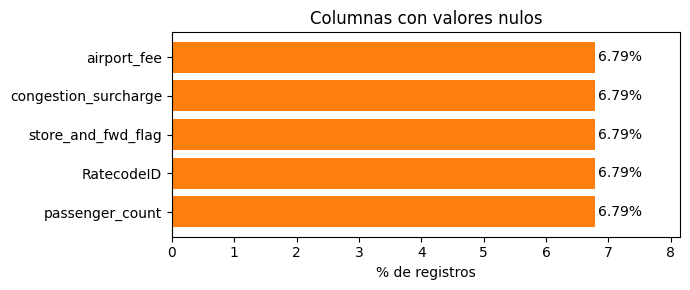

+------------+--------+---------------+--------------+-----------------+
|es_flex_fare|  viajes|nulos_pasajeros|nulos_ratecode|nulos_airport_fee|
+------------+--------+---------------+--------------+-----------------+
|        true| 5400588|        5400588|       5400588|          5400588|
|       false|74079358|              0|             0|                0|
+------------+--------+---------------+--------------+-----------------+



In [8]:
# Gráfica de nulos y verificación de su origen
nul = nulls[nulls["nulos"] > 0].sort_values("% nulos")
fig, ax = plt.subplots(figsize=(7, 3))
ax.barh(nul.index, nul["% nulos"], color="tab:orange")
for i, v in enumerate(nul["% nulos"]):
    ax.text(v + 0.05, i, f"{v:.2f}%", va="center")
ax.set_xlabel("% de registros"); ax.set_title("Columnas con valores nulos")
ax.set_xlim(0, nul["% nulos"].max() * 1.2)
plt.tight_layout(); plt.show()

# ¿Los nulos están en los mismos registros y coinciden con payment_type = 0 (Flex fare)?
(df.groupBy((F.col("payment_type") == 0).alias("es_flex_fare"))
   .agg(F.count("*").alias("viajes"),
        F.sum(F.col("passenger_count").isNull().cast("int")).alias("nulos_pasajeros"),
        F.sum(F.col("RatecodeID").isNull().cast("int")).alias("nulos_ratecode"),
        F.sum(F.col("airport_fee").isNull().cast("int")).alias("nulos_airport_fee"))
   .show())

In [9]:
# Estadísticas descriptivas de las variables numéricas principales
num_cols = ["passenger_count", "trip_distance", "fare_amount", "tip_amount", "total_amount"]
df.select(num_cols).describe().show()

+-------+------------------+------------------+------------------+------------------+------------------+
|summary|   passenger_count|     trip_distance|       fare_amount|        tip_amount|      total_amount|
+-------+------------------+------------------+------------------+------------------+------------------+
|  count|          74079358|          79479946|          79479946|          79479946|          79479946|
|   mean|1.3521591264330342|4.5484823260954075|19.390815694679052|3.4112182519625507|28.136060102550797|
| stddev|0.8552248017193663|345.09841911657566| 76.24313773458941| 4.119264513944731| 77.60955772889285|
|    min|               0.0|               0.0|           -2261.2|            -411.0|          -2265.45|
|    max|               9.0|         398608.62|         386983.63|            4174.0|         386987.63|
+-------+------------------+------------------+------------------+------------------+------------------+



In [11]:
# Duración del viaje en minutos y percentiles aproximados (approxQuantile es escalable)
df_eda = df.withColumn("duration_min",
    (F.unix_timestamp("tpep_dropoff_datetime") - F.unix_timestamp("tpep_pickup_datetime")) / 60)

q_cols = ["fare_amount", "trip_distance", "duration_min"]
probs = [0.01, 0.25, 0.5, 0.75, 0.99]
quant = df_eda.approxQuantile(q_cols, probs, 0.001)
pd.DataFrame(quant, index=q_cols, columns=[f"p{int(p*100)}" for p in probs])

,p1,p25,p50,p75,p99
fare_amount,-5.800000,9.300000,13.500000,22.600000,78.600000
trip_distance,0.000000,1.030000,1.780000,3.400000,20.100000
duration_min,0.516667,7.733333,12.833333,20.916667,69.083333


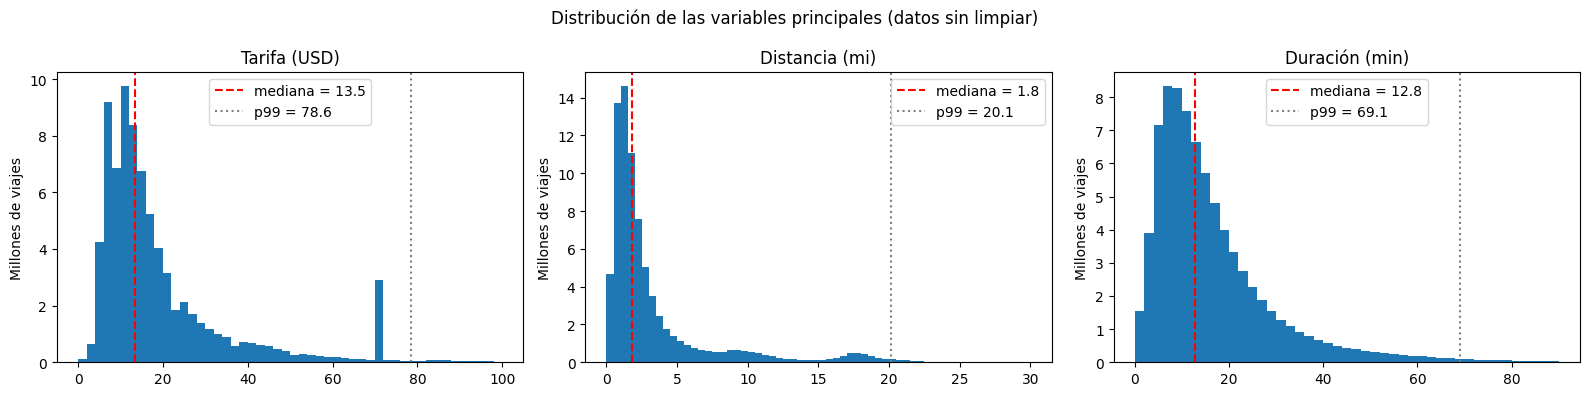

In [13]:
# Histogramas de tarifa, distancia y duración (el conteo por intervalo se hace en Spark)
def hist_spark(d, col, lo, hi, width):
    return (d.filter((F.col(col) >= lo) & (F.col(col) < hi))
             .groupBy((F.floor((F.col(col) - lo) / width) * width + lo).alias("bin")).count()
             .orderBy("bin").toPandas())

specs = [("fare_amount", 0, 100, 2, "Tarifa (USD)"),
         ("trip_distance", 0, 30, 0.5, "Distancia (mi)"),
         ("duration_min", 0, 90, 2, "Duración (min)")]

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for i, (c, lo, hi, w, nombre) in enumerate(specs):
    h = hist_spark(df_eda, c, lo, hi, w)
    ax[i].bar(h["bin"], h["count"] / 1e6, width=w, align="edge")
    ax[i].axvline(quant[i][2], color="red", ls="--", label=f"mediana = {quant[i][2]:.1f}")
    ax[i].axvline(quant[i][4], color="gray", ls=":", label=f"p99 = {quant[i][4]:.1f}")
    ax[i].set_title(nombre); ax[i].set_ylabel("Millones de viajes"); ax[i].legend()
plt.suptitle("Distribución de las variables principales (datos sin limpiar)")
plt.tight_layout(); plt.show()

In [14]:
# Conteo de registros anómalos que justifican la limpieza
anio = F.year("tpep_pickup_datetime")
anom_df = df_eda.select(
    F.sum((F.col("fare_amount") <= 0).cast("int")).alias("tarifa_<=0"),
    F.sum((F.col("trip_distance") <= 0).cast("int")).alias("distancia_<=0"),
    F.sum((F.col("duration_min") <= 0).cast("int")).alias("duracion_<=0"),
    F.sum((F.col("duration_min") > 180).cast("int")).alias("duracion_>3h"),
    F.sum((F.col("passenger_count") == 0).cast("int")).alias("pasajeros_=0"),
    F.sum(((anio < 2023) | (anio > 2024)).cast("int")).alias("fecha_fuera_de_rango"),
)
anom_df.show()

+----------+-------------+------------+------------+------------+--------------------+
|tarifa_<=0|distancia_<=0|duracion_<=0|duracion_>3h|pasajeros_=0|fecha_fuera_de_rango|
+----------+-------------+------------+------------+------------+--------------------+
|   1142787|      1549762|       29079|       60506|      984359|                 144|
+----------+-------------+------------+------------+------------+--------------------+



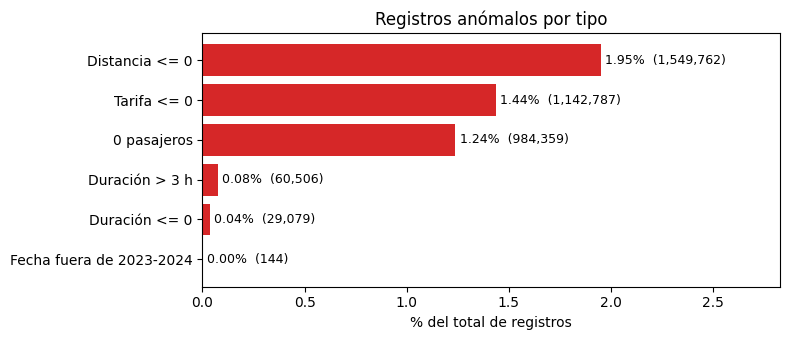

In [15]:
# Proporción de registros anómalos respecto al total
anom = pd.Series(anom_df.first().asDict())
etiquetas = {"tarifa_<=0": "Tarifa <= 0", "distancia_<=0": "Distancia <= 0", "duracion_<=0": "Duración <= 0",
             "duracion_>3h": "Duración > 3 h", "pasajeros_=0": "0 pasajeros", "fecha_fuera_de_rango": "Fecha fuera de 2023-2024"}
pct = (anom / n_raw * 100).rename(etiquetas).sort_values()

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.barh(pct.index, pct.values, color="tab:red")
for i, (v, n) in enumerate(zip(pct.values, anom.rename(etiquetas)[pct.index])):
    ax.text(v + 0.02, i, f"{v:.2f}%  ({n:,})", va="center", fontsize=9)
ax.set_xlabel("% del total de registros"); ax.set_xlim(0, pct.max() * 1.45)
ax.set_title("Registros anómalos por tipo")
plt.tight_layout(); plt.show()

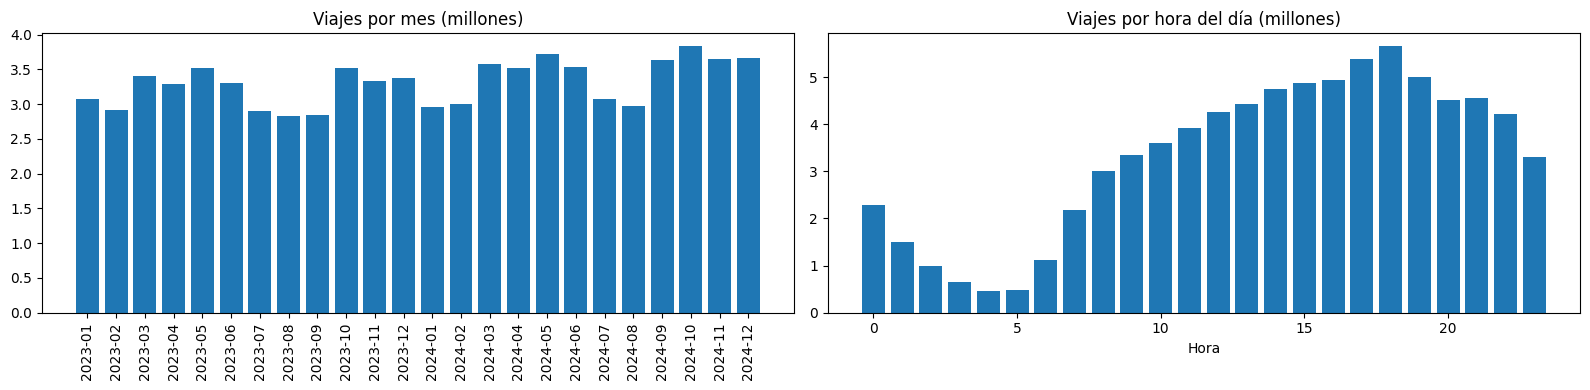

+------------+--------+
|payment_type|   count|
+------------+--------+
|           1|60309091|
|           2|11945147|
|           0| 5400588|
|           4| 1292509|
|           3|  532605|
|           5|       6|
+------------+--------+



In [16]:
# Distribución temporal de los viajes y métodos de pago
por_mes = (df.groupBy(F.date_format("tpep_pickup_datetime", "yyyy-MM").alias("mes")).count()
             .filter("mes BETWEEN '2023-01' AND '2024-12'").orderBy("mes").toPandas())
por_hora = (df.groupBy(F.hour("tpep_pickup_datetime").alias("hora")).count()
              .orderBy("hora").toPandas())

fig, ax = plt.subplots(1, 2, figsize=(16, 4))
ax[0].bar(por_mes["mes"], por_mes["count"] / 1e6)
ax[0].set_title("Viajes por mes (millones)"); ax[0].tick_params(axis="x", rotation=90)
ax[1].bar(por_hora["hora"], por_hora["count"] / 1e6)
ax[1].set_title("Viajes por hora del día (millones)"); ax[1].set_xlabel("Hora")
plt.tight_layout(); plt.show()

df.groupBy("payment_type").count().orderBy(F.desc("count")).show()

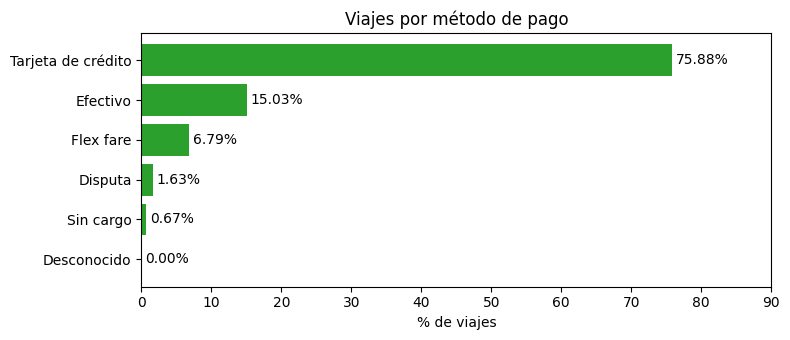

In [17]:
# Métodos de pago en porcentaje
pagos = {0: "Flex fare", 1: "Tarjeta de crédito", 2: "Efectivo", 3: "Sin cargo",
         4: "Disputa", 5: "Desconocido", 6: "Viaje anulado"}
pago_pd = df.groupBy("payment_type").count().toPandas()
pago_pd["metodo"] = pago_pd["payment_type"].map(pagos)
pago_pd["pct"] = pago_pd["count"] / pago_pd["count"].sum() * 100
pago_pd = pago_pd.sort_values("pct")

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.barh(pago_pd["metodo"], pago_pd["pct"], color="tab:green")
for i, v in enumerate(pago_pd["pct"]):
    ax.text(v + 0.5, i, f"{v:.2f}%", va="center")
ax.set_xlabel("% de viajes"); ax.set_xlim(0, 90); ax.set_title("Viajes por método de pago")
plt.tight_layout(); plt.show()

## Preprocesamiento

In [18]:
def preprocess(d, start, end):
    return (d
        .withColumn("duration_min",
                    (F.unix_timestamp("tpep_dropoff_datetime") - F.unix_timestamp("tpep_pickup_datetime")) / 60)
        .filter((F.col("tpep_pickup_datetime") >= start) & (F.col("tpep_pickup_datetime") < end))
        .dropna(subset=["passenger_count", "RatecodeID", "trip_distance", "fare_amount",
                        "PULocationID", "DOLocationID"])
        .filter(F.col("fare_amount").between(3, 250))
        .filter(F.col("trip_distance").between(0.1, 60))
        .filter(F.col("duration_min").between(1, 180))
        .filter(F.col("passenger_count").between(1, 6))
        .filter(F.col("RatecodeID").between(1, 6))
        .filter(F.col("total_amount") > 0)
        .withColumn("speed_mph", F.col("trip_distance") / (F.col("duration_min") / 60))
        .filter(F.col("speed_mph").between(1, 70))
        .withColumn("pickup_hour", F.hour("tpep_pickup_datetime"))
        .withColumn("day_of_week", F.dayofweek("tpep_pickup_datetime"))   # 1 = domingo ... 7 = sábado
        .withColumn("month", F.month("tpep_pickup_datetime"))
        .withColumn("year", F.year("tpep_pickup_datetime"))
        .withColumn("is_weekend", F.col("day_of_week").isin(1, 7).cast("int"))
        .withColumn("is_airport", (F.col("RatecodeID").isin(2, 3) |
                                   (F.coalesce(F.col("airport_fee"), F.lit(0)) > 0)).cast("int"))
        .withColumn("tip_pct", F.when(F.col("payment_type") == 1,
                                      F.col("tip_amount") / F.col("fare_amount")))
    )

df_clean = preprocess(df, "2023-01-01", "2025-01-01").cache()
n_clean = df_clean.count()
df.unpersist()   # libera memoria de los datos crudos

print(f"Registros originales: {n_raw:,}")
print(f"Registros limpios:    {n_clean:,}")
print(f"Eliminados:           {n_raw - n_clean:,} ({(1 - n_clean / n_raw) * 100:.2f}%)")

Registros originales: 79,479,946
Registros limpios:    70,225,235
Eliminados:           9,254,711 (11.64%)


Conservados según el embudo: 70,225,235 (debe coincidir con 70,225,235)


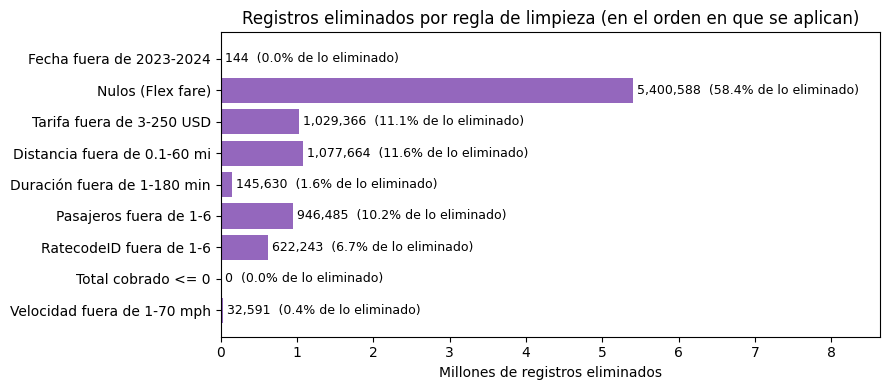

In [20]:
# ¿Qué regla eliminó cada registro? Cada viaje se cuenta solo en la PRIMERA regla que incumple
dur = (F.unix_timestamp("tpep_dropoff_datetime") - F.unix_timestamp("tpep_pickup_datetime")) / 60
spd = F.col("trip_distance") / (dur / 60)
reglas = [
    ("Fecha fuera de 2023-2024", ~((F.col("tpep_pickup_datetime") >= "2023-01-01") &
                                   (F.col("tpep_pickup_datetime") < "2025-01-01"))),
    ("Nulos (Flex fare)", F.col("passenger_count").isNull() | F.col("RatecodeID").isNull()),
    ("Tarifa fuera de 3-250 USD", ~F.col("fare_amount").between(3, 250)),
    ("Distancia fuera de 0.1-60 mi", ~F.col("trip_distance").between(0.1, 60)),
    ("Duración fuera de 1-180 min", ~dur.between(1, 180)),
    ("Pasajeros fuera de 1-6", ~F.col("passenger_count").between(1, 6)),
    ("RatecodeID fuera de 1-6", ~F.col("RatecodeID").between(1, 6)),
    ("Total cobrado <= 0", F.col("total_amount") <= 0),
    ("Velocidad fuera de 1-70 mph", ~spd.between(1, 70)),
]
motivo = F.lit("Conservado")
for nombre, cond in reversed(reglas):
    motivo = F.when(cond, nombre).otherwise(motivo)

embudo = df.groupBy(motivo.alias("motivo")).count().toPandas().set_index("motivo")["count"]
print(f"Conservados según el embudo: {embudo.get('Conservado', 0):,} (debe coincidir con {n_clean:,})")
elim = embudo.drop("Conservado").reindex([r[0] for r in reglas]).fillna(0)

fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(elim.index[::-1], elim.values[::-1] / 1e6, color="tab:purple")
for i, v in enumerate(elim.values[::-1]):
    ax.text(v / 1e6 + 0.05, i, f"{v:,.0f}  ({v / (n_raw - n_clean) * 100:.1f}% de lo eliminado)", va="center", fontsize=9)
ax.set_xlabel("Millones de registros eliminados"); ax.set_xlim(0, elim.max() / 1e6 * 1.6)
ax.set_title("Registros eliminados por regla de limpieza (en el orden en que se aplican)")
plt.tight_layout(); plt.show()

In [21]:
# Estadísticas después de la limpieza y correlación de cada variable con la tarifa
df_clean.select("trip_distance", "duration_min", "speed_mph", "fare_amount", "tip_pct").describe().show()

corr_cols = ["trip_distance", "duration_min", "passenger_count", "pickup_hour", "is_weekend", "is_airport"]
df_clean.select([F.round(F.corr(c, "fare_amount"), 3).alias(c) for c in corr_cols]).show()

+-------+-----------------+------------------+------------------+------------------+------------------+
|summary|    trip_distance|      duration_min|         speed_mph|       fare_amount|           tip_pct|
+-------+-----------------+------------------+------------------+------------------+------------------+
|  count|         70225235|          70225235|          70225235|          70225235|          58217426|
|   mean|3.436068564811491|16.418700931842654|11.123102460469696| 19.53643070798454|0.2511801063809325|
| stddev|4.481529389894712|13.109645327968686| 6.478241661072111|17.528384987956503|0.1366556868359742|
|    min|              0.1|               1.0|               1.0|               3.0|               0.0|
|    max|             60.0|179.98333333333332|              70.0|             250.0| 98.03921568627452|
+-------+-----------------+------------------+------------------+------------------+------------------+

+-------------+------------+---------------+-----------+-------

Correlación distancia vs duración: 0.804


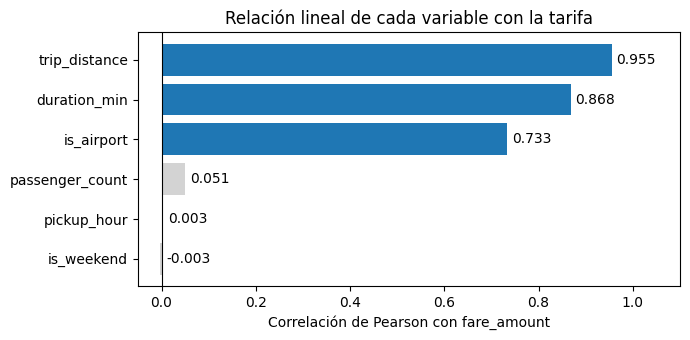

In [22]:
# Correlación de cada variable con la tarifa + correlación entre distancia y duración
corr_pd = (df_clean.select([F.corr(c, "fare_amount").alias(c) for c in corr_cols] +
                           [F.corr("trip_distance", "duration_min").alias("dist_vs_dur")])
                   .toPandas().T[0])
print(f"Correlación distancia vs duración: {corr_pd['dist_vs_dur']:.3f}")
corr_pd = corr_pd.drop("dist_vs_dur").sort_values()

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.barh(corr_pd.index, corr_pd.values, color=["tab:blue" if v >= 0.5 else "lightgray" for v in corr_pd.values])
for i, v in enumerate(corr_pd.values):
    ax.text(max(v, 0) + 0.01, i, f"{v:.3f}", va="center")
ax.axvline(0, color="black", lw=0.8); ax.set_xlim(-0.05, 1.1)
ax.set_xlabel("Correlación de Pearson con fare_amount"); ax.set_title("Relación lineal de cada variable con la tarifa")
plt.tight_layout(); plt.show()

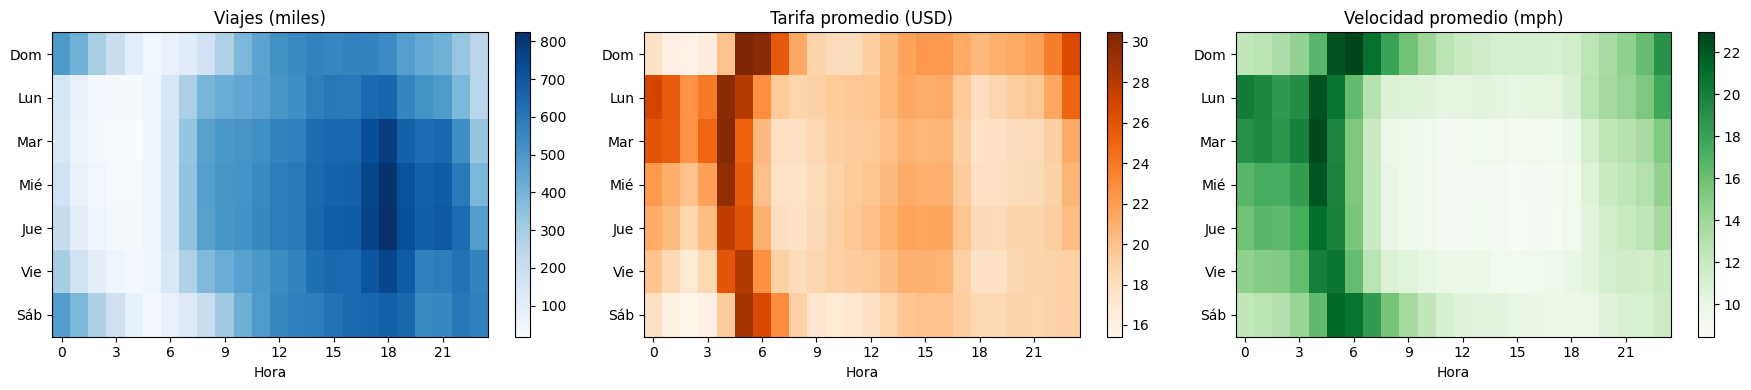

In [23]:
# Mapa de calor: viajes, tarifa promedio y velocidad promedio por día y hora (datos limpios)
dh = (df_clean.groupBy("day_of_week", "pickup_hour")
              .agg(F.count("*").alias("viajes"), F.avg("fare_amount").alias("tarifa"), F.avg("speed_mph").alias("velocidad"))
              .toPandas())
nombres_dia = ["Dom", "Lun", "Mar", "Mié", "Jue", "Vie", "Sáb"]

fig, ax = plt.subplots(1, 3, figsize=(18, 4))
for a, (col, titulo, cmap) in zip(ax, [("viajes", "Viajes (miles)", "Blues"),
                                       ("tarifa", "Tarifa promedio (USD)", "Oranges"),
                                       ("velocidad", "Velocidad promedio (mph)", "Greens")]):
    m = dh.pivot(index="day_of_week", columns="pickup_hour", values=col).sort_index()
    if col == "viajes":
        m = m / 1e3
    im = a.imshow(m.values, aspect="auto", cmap=cmap)
    a.set_yticks(range(7)); a.set_yticklabels(nombres_dia)
    a.set_xticks(range(0, 24, 3)); a.set_xlabel("Hora"); a.set_title(titulo)
    fig.colorbar(im, ax=a)
plt.tight_layout(); plt.show()

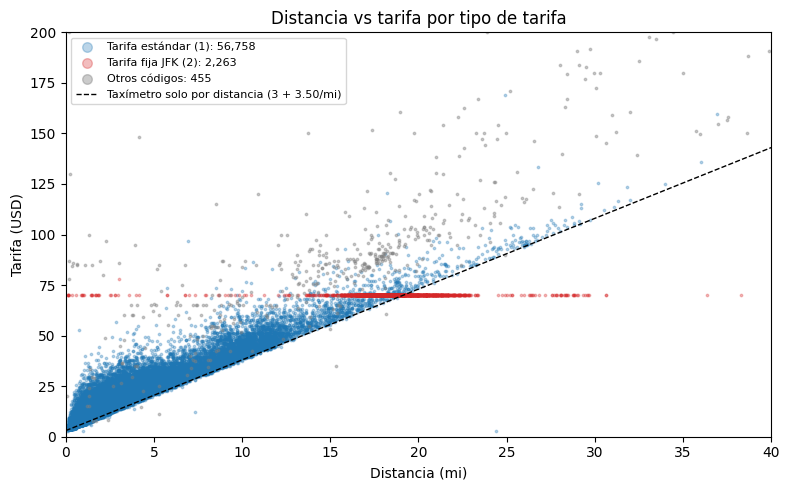

In [24]:
# Dispersión distancia vs tarifa por tipo de tarifa (muestra de ~60 mil viajes)
s_sc = (df_clean.sample(fraction=60_000 / n_clean, seed=7)
                .select("trip_distance", "fare_amount", "RatecodeID").toPandas())
grupos = {1.0: ("Tarifa estándar (1)", "tab:blue"), 2.0: ("Tarifa fija JFK (2)", "tab:red")}

plt.figure(figsize=(8, 5))
for code_, (nombre, color) in grupos.items():
    g = s_sc[s_sc["RatecodeID"] == code_]
    plt.scatter(g["trip_distance"], g["fare_amount"], s=3, alpha=0.3, color=color, label=f"{nombre}: {len(g):,}")
g = s_sc[~s_sc["RatecodeID"].isin(list(grupos))]
plt.scatter(g["trip_distance"], g["fare_amount"], s=3, alpha=0.4, color="tab:gray", label=f"Otros códigos: {len(g):,}")
x = [0, 40]
plt.plot(x, [3 + 3.5 * v for v in x], "k--", lw=1, label="Taxímetro solo por distancia (3 + 3.50/mi)")
plt.xlim(0, 40); plt.ylim(0, 200)
plt.xlabel("Distancia (mi)"); plt.ylabel("Tarifa (USD)"); plt.title("Distancia vs tarifa por tipo de tarifa")
plt.legend(markerscale=4, fontsize=8); plt.tight_layout(); plt.show()

## Exportación de tablas agregadas a CSV para Tableau

In [25]:
import glob, shutil

OUT = "/content/tableau"
os.makedirs(OUT, exist_ok=True)

def to_csv(d, name):
    tmp = f"/content/tmp_{name}"
    (d.coalesce(1).write.mode("overwrite")
       .option("header", True).option("timestampFormat", "yyyy-MM-dd HH:mm:ss")
       .csv(tmp))
    shutil.move(glob.glob(f"{tmp}/part-*.csv")[0], f"{OUT}/{name}.csv")
    shutil.rmtree(tmp)
    print(f"{name}.csv -> {os.path.getsize(f'{OUT}/{name}.csv') / 1e6:.2f} MB")

subprocess.run(["wget", "-q", "-nc", "https://d37ci6vzurychx.cloudfront.net/misc/taxi_zone_lookup.csv", "-P", "/content"])
zonas = spark.read.csv("/content/taxi_zone_lookup.csv", header=True, inferSchema=True)
zonas_pu = F.broadcast(zonas.select(F.col("LocationID").alias("PULocationID"),
                                    F.col("Borough").alias("pu_borough"), F.col("Zone").alias("pu_zone")))
zonas_do = F.broadcast(zonas.select(F.col("LocationID").alias("DOLocationID"),
                                    F.col("Borough").alias("do_borough"), F.col("Zone").alias("do_zone")))

dias  = {1: "Domingo", 2: "Lunes", 3: "Martes", 4: "Miércoles", 5: "Jueves", 6: "Viernes", 7: "Sábado"}
pagos = {0: "Flex fare", 1: "Tarjeta de crédito", 2: "Efectivo", 3: "Sin cargo",
         4: "Disputa", 5: "Desconocido", 6: "Viaje anulado"}

def map_col(col, mapping):
    return F.create_map([F.lit(x) for kv in mapping.items() for x in kv])[F.col(col)]

def kpis():
    return [F.count("*").alias("viajes"),
            F.round(F.avg("fare_amount"), 2).alias("tarifa_promedio"),
            F.round(F.avg("trip_distance"), 2).alias("distancia_promedio_mi"),
            F.round(F.avg("duration_min"), 2).alias("duracion_promedio_min"),
            F.round(F.avg("tip_pct") * 100, 2).alias("propina_promedio_pct"),
            F.round(F.sum("total_amount"), 2).alias("ingreso_total_usd")]

In [26]:
# 1) Tendencia mensual
to_csv(df_clean.groupBy("year", "month").agg(*kpis())
               .withColumn("fecha", F.make_date("year", "month", F.lit(1)))
               .orderBy("fecha"), "viajes_por_mes")

# 2) Día de la semana x hora (mapa de calor)
to_csv(df_clean.groupBy("day_of_week", "pickup_hour").agg(*kpis())
               .withColumn("dia", map_col("day_of_week", dias))
               .orderBy("day_of_week", "pickup_hour"), "viajes_por_dia_hora")

# 3) Zonas de origen
to_csv(df_clean.groupBy("PULocationID").agg(*kpis()).join(zonas_pu, "PULocationID", "left")
               .orderBy(F.desc("viajes")), "zonas_origen")

# 4) Rutas más frecuentes (top 200)
to_csv(df_clean.groupBy("PULocationID", "DOLocationID").agg(*kpis())
               .orderBy(F.desc("viajes")).limit(200)
               .join(zonas_pu, "PULocationID", "left").join(zonas_do, "DOLocationID", "left"), "rutas_top")

# 5) Métodos de pago
to_csv(df_clean.groupBy("payment_type").agg(*kpis())
               .withColumn("metodo_pago", map_col("payment_type", pagos)), "metodos_pago")

# 6) Muestra aleatoria de ~200 mil viajes (para dispersión distancia vs tarifa, etc.)
muestra = (df_clean.sample(fraction=min(1.0, 200_000 / n_clean), seed=42)
           .select("tpep_pickup_datetime", "pickup_hour", "day_of_week", "PULocationID", "DOLocationID",
                   "passenger_count", "trip_distance", F.round("duration_min", 2).alias("duration_min"),
                   F.round("speed_mph", 2).alias("speed_mph"), "fare_amount", "tip_amount", "total_amount",
                   "payment_type", "is_airport")
           .withColumn("dia", map_col("day_of_week", dias))
           .withColumn("metodo_pago", map_col("payment_type", pagos))
           .join(zonas_pu, "PULocationID", "left").join(zonas_do, "DOLocationID", "left"))
to_csv(muestra, "muestra_viajes")

viajes_por_mes.csv -> 0.00 MB
viajes_por_dia_hora.csv -> 0.01 MB
zonas_origen.csv -> 0.02 MB
rutas_top.csv -> 0.02 MB
metodos_pago.csv -> 0.00 MB
muestra_viajes.csv -> 30.25 MB


## Modelo de regresión con MLlib

- **Variable objetivo:** `fare_amount` (USD)
- **Variables de entrada:** distancia, duración, pasajeros, hora, día de la semana, mes, fin de semana, tipo de tarifa (`RatecodeID`), zonas de origen y destino, y si el viaje es de aeropuerto.
- **Muestra para entrenamiento:** 2% de los datos limpios (~1.4 millones de viajes) para que el entrenamiento quepa en Colab gratuito; la muestra sigue siendo mucho mayor que un dataset tradicional.
- **División:** 80% entrenamiento / 20% prueba.
- **Modelos:** Regresión Lineal (línea base, con variables estandarizadas) y Random Forest Regressor, ambos dentro de un `Pipeline` de MLlib.

In [28]:
from pyspark.ml import Pipeline
from pyspark.ml.feature import VectorAssembler, StandardScaler
from pyspark.ml.regression import LinearRegression, RandomForestRegressor
from pyspark.ml.evaluation import RegressionEvaluator
import time

features = ["trip_distance", "duration_min", "passenger_count", "pickup_hour", "day_of_week", "month",
            "is_weekend", "RatecodeID", "PULocationID", "DOLocationID", "is_airport"]
label = "fare_amount"

model_df = df_clean.select(features + [label, "tpep_pickup_datetime"]).sample(fraction=0.02, seed=42)
train, test = model_df.randomSplit([0.8, 0.2], seed=42)
train, test = train.cache(), test.cache()
print(f"Entrenamiento: {train.count():,} | Prueba: {test.count():,}")

Entrenamiento: 1,122,956 | Prueba: 280,609


### Distribución de las observaciones en entrenamiento y prueba

Antes de entrenar conviene revisar cómo quedaron repartidas las observaciones: si la muestra del 2% y la división 80/20 conservan la misma proporción de viajes cortos, largos y de aeropuerto que los 70 millones de datos limpios. Si no fuera así, las métricas de prueba no representarían el desempeño real.

,Datos limpios (70M),Entrenamiento,Prueba
rango,,,
0-1 mi,21.94,21.99,21.84
1-3 mi,49.93,49.85,50.03
3-5 mi,11.15,11.20,11.18
5-10 mi,8.38,8.36,8.36
10-20 mi,7.50,7.51,7.51
20+ mi,1.10,1.10,1.09


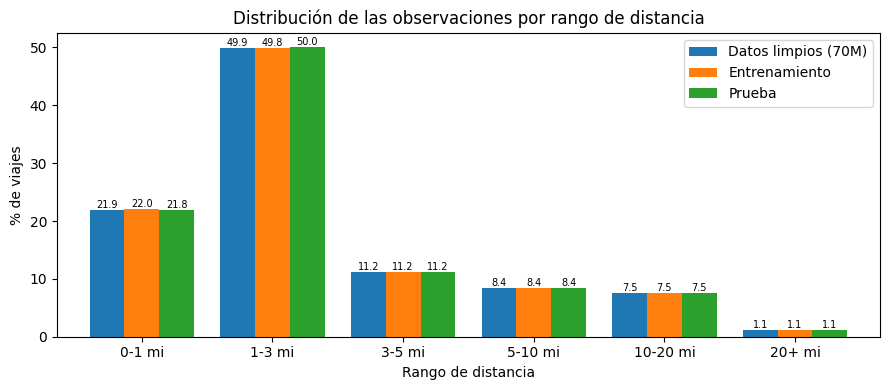

Datos limpios  -> aeropuerto: 10.30% | tarifa fija JFK: 3.82%
Entrenamiento  -> aeropuerto: 10.32% | tarifa fija JFK: 3.82%
Prueba         -> aeropuerto: 10.23% | tarifa fija JFK: 3.84%


In [29]:
def rango_distancia(col="trip_distance"):
    d = F.col(col)
    return (F.when(d < 1, "0-1 mi").when(d < 3, "1-3 mi").when(d < 5, "3-5 mi")
             .when(d < 10, "5-10 mi").when(d < 20, "10-20 mi").otherwise("20+ mi"))

orden_rangos = ["0-1 mi", "1-3 mi", "3-5 mi", "5-10 mi", "10-20 mi", "20+ mi"]

def proporciones(d, nombre):
    p = d.groupBy(rango_distancia().alias("rango")).count().toPandas().set_index("rango")["count"]
    return (p / p.sum() * 100).rename(nombre)

dist_obs = pd.concat([proporciones(df_clean, "Datos limpios (70M)"),
                      proporciones(train, "Entrenamiento"),
                      proporciones(test, "Prueba")], axis=1).reindex(orden_rangos)
display(dist_obs.round(2))

ax = dist_obs.plot.bar(figsize=(9, 4), rot=0, width=0.8)
ax.set_ylabel("% de viajes"); ax.set_xlabel("Rango de distancia")
ax.set_title("Distribución de las observaciones por rango de distancia")
for cont in ax.containers:
    ax.bar_label(cont, fmt="%.1f", fontsize=7)
plt.tight_layout(); plt.show()

# Proporción de viajes de aeropuerto y de tarifa fija JFK en cada conjunto
for nombre, d in [("Datos limpios", df_clean), ("Entrenamiento", train), ("Prueba", test)]:
    r = d.agg(F.avg("is_airport").alias("aero"), F.avg((F.col("RatecodeID") == 2).cast("int")).alias("jfk")).first()
    print(f"{nombre:14s} -> aeropuerto: {r['aero'] * 100:.2f}% | tarifa fija JFK: {r['jfk'] * 100:.2f}%")

In [30]:
assembler = VectorAssembler(inputCols=features, outputCol="features")

lr_pipe = Pipeline(stages=[
    assembler,
    StandardScaler(inputCol="features", outputCol="scaled", withMean=True, withStd=True),
    LinearRegression(featuresCol="scaled", labelCol=label, maxIter=50, regParam=0.01),
])
rf_pipe = Pipeline(stages=[
    assembler,
    RandomForestRegressor(featuresCol="features", labelCol=label, numTrees=30, maxDepth=10,
                          subsamplingRate=0.8, seed=42),
])

t = time.time(); lr_model = lr_pipe.fit(train); print(f"Regresión Lineal entrenada en {time.time() - t:.0f} s")
t = time.time(); rf_model = rf_pipe.fit(train); print(f"Random Forest entrenado en {time.time() - t:.0f} s")

Regresión Lineal entrenada en 16 s
Random Forest entrenado en 92 s


## Evaluación del modelo

Se usa `RegressionEvaluator` de MLlib sobre el conjunto de prueba con tres métricas:
- **RMSE:** error cuadrático medio (en USD), penaliza más los errores grandes.
- **MAE:** error absoluto promedio (en USD).
- **R²:** proporción de la varianza de la tarifa explicada por el modelo.

In [31]:
def evaluate(pred, nombre, conjunto):
    ev = RegressionEvaluator(labelCol=label, predictionCol="prediction")
    return {"modelo": nombre, "conjunto": conjunto,
            "rmse": round(ev.evaluate(pred, {ev.metricName: "rmse"}), 3),
            "mae":  round(ev.evaluate(pred, {ev.metricName: "mae"}), 3),
            "r2":   round(ev.evaluate(pred, {ev.metricName: "r2"}), 4)}

pred_lr = lr_model.transform(test).cache()
pred_rf = rf_model.transform(test).cache()

metricas = [evaluate(pred_lr, "Regresión Lineal", "Prueba 2023-2024"),
            evaluate(pred_rf, "Random Forest", "Prueba 2023-2024")]
pd.DataFrame(metricas)

,modelo,conjunto,rmse,mae,r2
0,Regresión Lineal,Prueba 2023-2024,3.849,1.661,0.9518
1,Random Forest,Prueba 2023-2024,2.560,0.884,0.9787


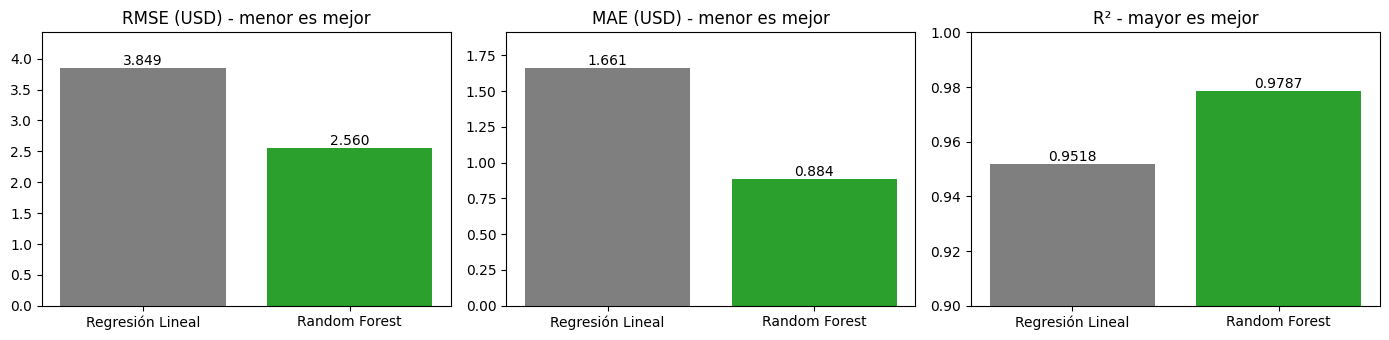

In [32]:
# Comparación visual de las métricas en el conjunto de prueba
m = pd.DataFrame(metricas).set_index("modelo")
fig, ax = plt.subplots(1, 3, figsize=(14, 3.5))
for a, (met, titulo) in zip(ax, [("rmse", "RMSE (USD) - menor es mejor"), ("mae", "MAE (USD) - menor es mejor"),
                                 ("r2", "R² - mayor es mejor")]):
    barras = a.bar(m.index, m[met], color=["tab:gray", "tab:green"])
    a.bar_label(barras, fmt="%.3f" if met != "r2" else "%.4f")
    a.set_title(titulo)
    a.set_ylim(0.9, 1.0) if met == "r2" else a.set_ylim(0, m[met].max() * 1.15)
plt.tight_layout(); plt.show()

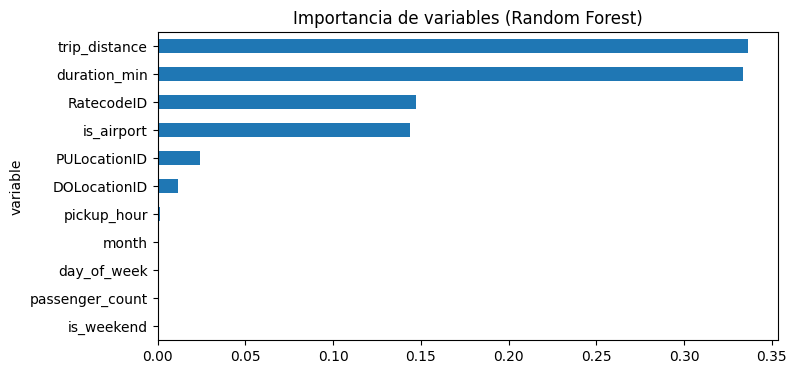

,variable,importancia
0,trip_distance,0.336439
1,duration_min,0.333868
7,RatecodeID,0.147255
10,is_airport,0.143840
8,PULocationID,0.024073
9,DOLocationID,0.011545
3,pickup_hour,0.001586
5,month,0.000557
4,day_of_week,0.000430
2,passenger_count,0.000281


In [33]:
# Importancia de variables del Random Forest
rf = rf_model.stages[-1]
imp = (pd.DataFrame({"variable": features, "importancia": rf.featureImportances.toArray()})
         .sort_values("importancia", ascending=False))
imp.plot.barh(x="variable", y="importancia", legend=False, figsize=(8, 4), title="Importancia de variables (Random Forest)")
plt.gca().invert_yaxis(); plt.show()
imp

+---------------+------+----+--------------------+------------------------+
|rango_distancia|viajes| mae|tarifa_real_promedio|tarifa_predicha_promedio|
+---------------+------+----+--------------------+------------------------+
|         0-1 mi| 61283|0.46|                 7.7|                    7.91|
|         1-3 mi|140385|0.52|               13.43|                   13.48|
|         3-5 mi| 31368|1.02|               22.74|                   22.55|
|        5-10 mi| 23445|1.91|                35.1|                   35.09|
|       10-20 mi| 21064|2.32|               62.65|                   62.51|
|         20+ mi|  3064|7.21|               88.06|                   84.44|
+---------------+------+----+--------------------+------------------------+



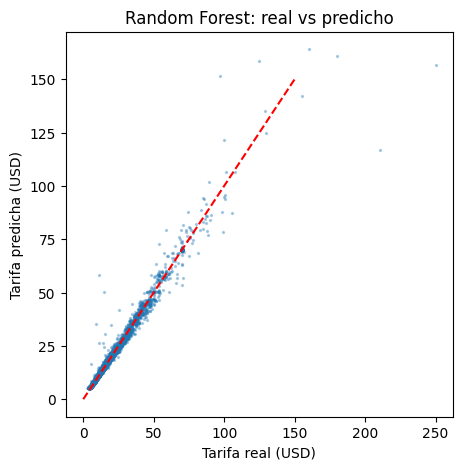

In [34]:
# Análisis de error por rango de distancia (Random Forest)
dist = F.col("trip_distance")
err = (pred_rf
       .withColumn("abs_error", F.abs(F.col("prediction") - F.col(label)))
       .withColumn("rango_distancia",
                   F.when(dist < 1, "0-1 mi").when(dist < 3, "1-3 mi").when(dist < 5, "3-5 mi")
                    .when(dist < 10, "5-10 mi").when(dist < 20, "10-20 mi").otherwise("20+ mi"))
       .groupBy("rango_distancia")
       .agg(F.count("*").alias("viajes"),
            F.round(F.avg("abs_error"), 2).alias("mae"),
            F.round(F.avg(label), 2).alias("tarifa_real_promedio"),
            F.round(F.avg("prediction"), 2).alias("tarifa_predicha_promedio"))
       .orderBy("tarifa_real_promedio"))
err.show()

# Real vs predicho (muestra pequeña para graficar)
s = pred_rf.select(label, "prediction").sample(fraction=0.02, seed=1).toPandas()
plt.figure(figsize=(5, 5)); plt.scatter(s[label], s["prediction"], s=2, alpha=0.3)
plt.plot([0, 150], [0, 150], "r--"); plt.xlabel("Tarifa real (USD)"); plt.ylabel("Tarifa predicha (USD)")
plt.title("Random Forest: real vs predicho"); plt.show()

rf_model.write().overwrite().save("/content/modelo_rf_taxi")

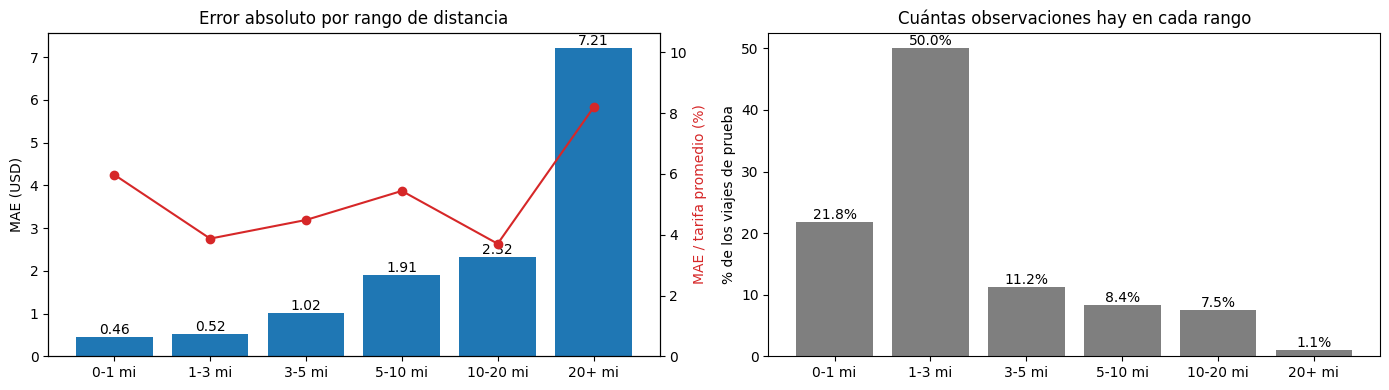

In [35]:
# Error absoluto y relativo por rango de distancia
e = err.toPandas().set_index("rango_distancia").reindex(orden_rangos)
e["mae_pct"] = e["mae"] / e["tarifa_real_promedio"] * 100
e["pct_viajes"] = e["viajes"] / e["viajes"].sum() * 100

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
b = ax[0].bar(e.index, e["mae"], color="tab:blue"); ax[0].bar_label(b, fmt="%.2f")
ax[0].set_ylabel("MAE (USD)"); ax[0].set_title("Error absoluto por rango de distancia")
ax2 = ax[0].twinx(); ax2.plot(e.index, e["mae_pct"], "o-", color="tab:red"); ax2.set_ylabel("MAE / tarifa promedio (%)", color="tab:red")
ax2.set_ylim(0, e["mae_pct"].max() * 1.3)
b = ax[1].bar(e.index, e["pct_viajes"], color="tab:gray"); ax[1].bar_label(b, fmt="%.1f%%")
ax[1].set_ylabel("% de los viajes de prueba"); ax[1].set_title("Cuántas observaciones hay en cada rango")
plt.tight_layout(); plt.show()

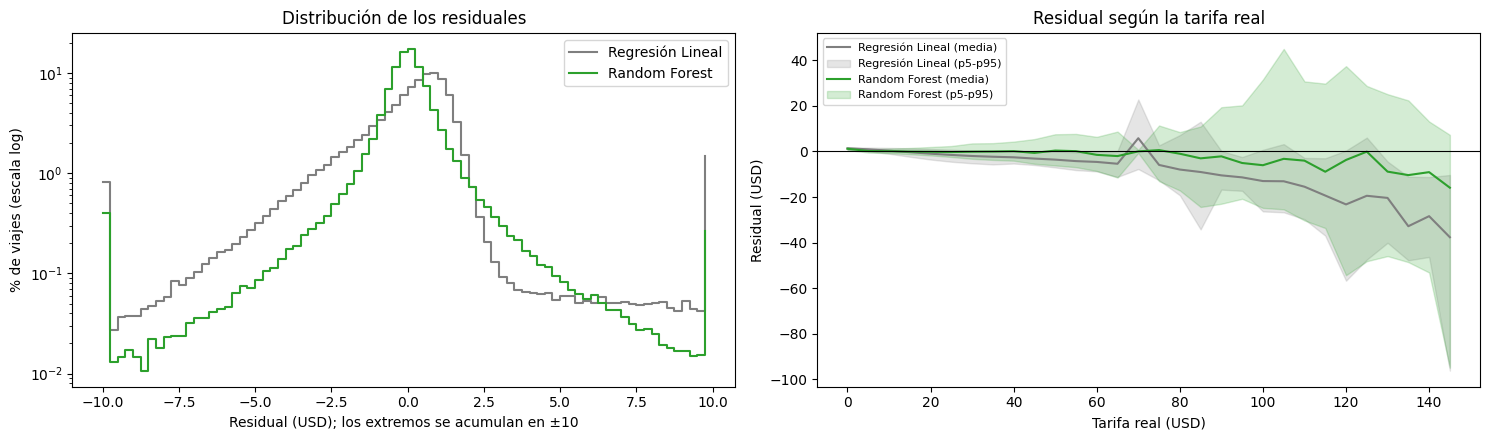

In [36]:
# Análisis de residuales (residual = predicción - tarifa real), Regresión Lineal vs Random Forest
def residuales(pred):
    return pred.withColumn("residual", F.col("prediction") - F.col(label))

def hist_residual(pred, w=0.25, lim=10):
    r = residuales(pred).withColumn("residual", F.greatest(F.lit(-lim), F.least(F.lit(lim - 1e-9), "residual")))
    return (r.groupBy((F.floor(F.col("residual") / w) * w).alias("bin")).count().orderBy("bin").toPandas())

def residual_por_tarifa(pred, w=5):
    return (residuales(pred).filter(F.col(label) < 150)
            .groupBy((F.floor(F.col(label) / w) * w).alias("tarifa"))
            .agg(F.avg("residual").alias("media"),
                 F.percentile_approx("residual", 0.05).alias("p5"),
                 F.percentile_approx("residual", 0.95).alias("p95"))
            .orderBy("tarifa").toPandas())

fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
for pred, nombre, color in [(pred_lr, "Regresión Lineal", "tab:gray"), (pred_rf, "Random Forest", "tab:green")]:
    h = hist_residual(pred)
    ax[0].step(h["bin"], h["count"] / h["count"].sum() * 100, where="post", color=color, label=nombre)
    r = residual_por_tarifa(pred)
    ax[1].plot(r["tarifa"], r["media"], color=color, label=f"{nombre} (media)")
    ax[1].fill_between(r["tarifa"], r["p5"], r["p95"], color=color, alpha=0.2, label=f"{nombre} (p5-p95)")
ax[0].set_yscale("log"); ax[0].set_xlabel("Residual (USD); los extremos se acumulan en ±10")
ax[0].set_ylabel("% de viajes (escala log)"); ax[0].set_title("Distribución de los residuales"); ax[0].legend()
ax[1].axhline(0, color="black", lw=0.8); ax[1].set_xlabel("Tarifa real (USD)"); ax[1].set_ylabel("Residual (USD)")
ax[1].set_title("Residual según la tarifa real"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

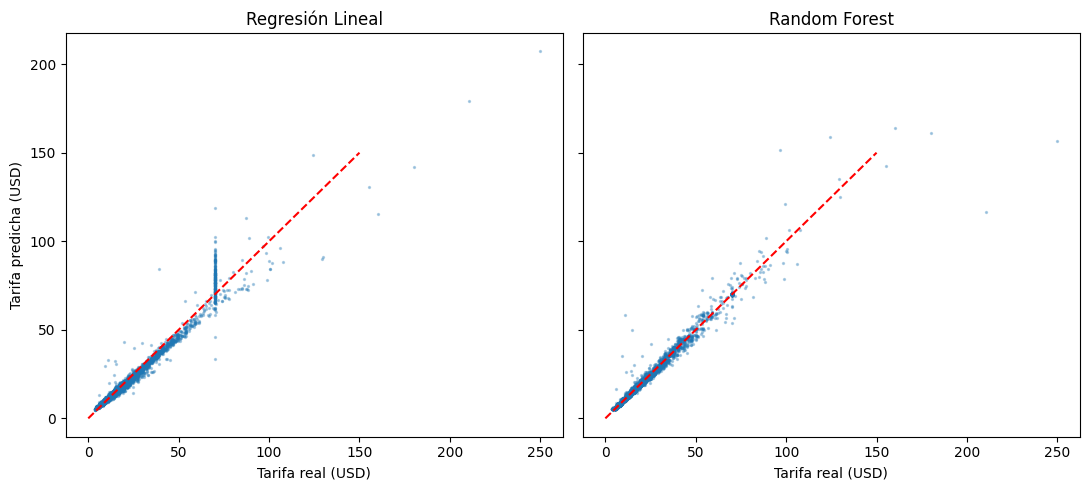

In [37]:
# Real vs predicho de ambos modelos lado a lado (muestra pequeña para graficar)
fig, ax = plt.subplots(1, 2, figsize=(11, 5), sharex=True, sharey=True)
for a, (pred, nombre) in zip(ax, [(pred_lr, "Regresión Lineal"), (pred_rf, "Random Forest")]):
    s2 = pred.select(label, "prediction").sample(fraction=0.02, seed=1).toPandas()
    a.scatter(s2[label], s2["prediction"], s=2, alpha=0.3)
    a.plot([0, 150], [0, 150], "r--"); a.set_title(nombre); a.set_xlabel("Tarifa real (USD)")
ax[0].set_ylabel("Tarifa predicha (USD)")
plt.tight_layout(); plt.show()

## Predicciones con datos nuevos


In [38]:
subprocess.run(["wget", "-q", "-nc", url.format(2025, 1), "-P", "/content/data_nuevo"])
df_new = preprocess(load("/content/data_nuevo/yellow_tripdata_2025-01.parquet"), "2025-01-01", "2025-02-01")

pred_new = rf_model.transform(df_new).cache()
print(f"Viajes nuevos (ene-2025): {pred_new.count():,}")

metricas.append(evaluate(pred_new, "Random Forest", "Datos nuevos ene-2025"))
metricas.append(evaluate(lr_model.transform(df_new), "Regresión Lineal", "Datos nuevos ene-2025"))
display(pd.DataFrame(metricas))

pred_new.select("tpep_pickup_datetime", "trip_distance", F.round("duration_min", 1).alias("duration_min"),
                "fare_amount", F.round("prediction", 2).alias("prediccion")).show(10)

Viajes nuevos (ene-2025): 2,763,660


,modelo,conjunto,rmse,mae,r2
0,Regresión Lineal,Prueba 2023-2024,3.849,1.661,0.9518
1,Random Forest,Prueba 2023-2024,2.560,0.884,0.9787
2,Random Forest,Datos nuevos ene-2025,2.395,0.810,0.9785
3,Regresión Lineal,Datos nuevos ene-2025,3.305,1.364,0.9591


+--------------------+-------------+------------+-----------+----------+
|tpep_pickup_datetime|trip_distance|duration_min|fare_amount|prediccion|
+--------------------+-------------+------------+-----------+----------+
| 2025-01-01 00:18:38|          1.6|         8.4|       10.0|     10.66|
| 2025-01-01 00:32:40|          0.5|         2.6|        5.1|      5.17|
| 2025-01-01 00:44:04|          0.6|         2.0|        5.1|      5.53|
| 2025-01-01 00:14:27|         0.52|         5.6|        7.2|      6.64|
| 2025-01-01 00:21:34|         0.66|         3.5|        5.8|      6.18|
| 2025-01-01 00:48:24|         2.63|        20.0|       19.1|     19.15|
| 2025-01-01 00:00:02|         1.71|         9.6|       11.4|     11.29|
| 2025-01-01 00:20:28|         2.29|         7.6|       11.4|     11.15|
| 2025-01-01 00:33:58|         0.56|         3.4|        5.8|      5.65|
| 2025-01-01 00:42:40|         1.99|        13.0|       14.2|     14.01|
+--------------------+-------------+------------+--

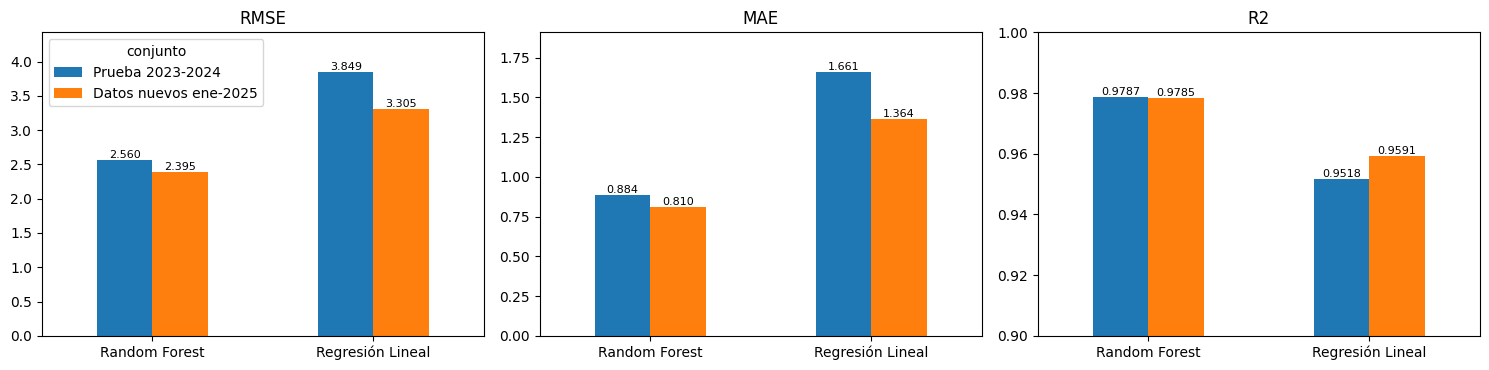

In [39]:
# Métricas en prueba 2023-2024 vs datos nuevos ene-2025
mm = pd.DataFrame(metricas)
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
for a, met in zip(ax, ["rmse", "mae", "r2"]):
    p = mm.pivot(index="modelo", columns="conjunto", values=met)[["Prueba 2023-2024", "Datos nuevos ene-2025"]]
    p.plot.bar(ax=a, rot=0, color=["tab:blue", "tab:orange"], legend=(met == "rmse"))
    for cont in a.containers:
        a.bar_label(cont, fmt="%.3f" if met != "r2" else "%.4f", fontsize=8)
    a.set_title(met.upper()); a.set_xlabel("")
    a.set_ylim(0.9, 1.0) if met == "r2" else a.set_ylim(0, p.values.max() * 1.15)
plt.tight_layout(); plt.show()

In [40]:
ejemplos = spark.createDataFrame([
    # descripcion, distancia, duración, pasajeros, hora, día(1=dom), mes, fin de semana, RatecodeID, PU, DO, aeropuerto
    ("Times Square -> JFK, viernes 18h (tarifa fija)", 17.0, 55.0, 1.0, 18, 6, 3, 0, 2.0, 230, 132, 1),
    ("Viaje corto en Midtown, martes 9h",               1.2,  9.0, 1.0,  9, 3, 3, 0, 1.0, 161, 162, 0),
    ("Upper East Side -> Financial District, domingo",  5.5, 22.0, 2.0, 14, 1, 3, 1, 1.0, 236,  87, 0),
    ("LaGuardia -> Midtown, lunes 8h",                  9.0, 35.0, 1.0,  8, 2, 3, 0, 1.0, 138, 161, 1),
], ["descripcion"] + features)

rf_model.transform(ejemplos).select("descripcion", "trip_distance", "duration_min",
                                    F.round("prediction", 2).alias("tarifa_predicha_usd")).show(truncate=False)

+----------------------------------------------+-------------+------------+-------------------+
|descripcion                                   |trip_distance|duration_min|tarifa_predicha_usd|
+----------------------------------------------+-------------+------------+-------------------+
|Times Square -> JFK, viernes 18h (tarifa fija)|17.0         |55.0        |70.02              |
|Viaje corto en Midtown, martes 9h             |1.2          |9.0         |9.96               |
|Upper East Side -> Financial District, domingo|5.5          |22.0        |25.5               |
|LaGuardia -> Midtown, lunes 8h                |9.0          |35.0        |40.88              |
+----------------------------------------------+-------------+------------+-------------------+



## Exportación de resultados del modelo y descarga de todos los CSV

In [41]:
to_csv(spark.createDataFrame(pd.DataFrame(metricas)), "metricas_modelos")
to_csv(spark.createDataFrame(imp), "importancia_variables")
to_csv(err, "error_por_distancia")

cols_pred = ["tpep_pickup_datetime", "pickup_hour", "day_of_week", "PULocationID", "DOLocationID",
             "trip_distance", "duration_min", "fare_amount", "prediction"]
pred_export = (pred_rf.select(cols_pred).sample(fraction=min(1.0, 100_000 / pred_rf.count()), seed=42)
                      .withColumn("conjunto", F.lit("Prueba 2023-2024"))
               .unionByName(pred_new.select(cols_pred).sample(fraction=min(1.0, 100_000 / pred_new.count()), seed=42)
                      .withColumn("conjunto", F.lit("Nuevos ene-2025")))
               .withColumn("prediction", F.round("prediction", 2))
               .withColumn("duration_min", F.round("duration_min", 2))
               .withColumn("error", F.round(F.col("prediction") - F.col("fare_amount"), 2))
               .withColumn("dia", map_col("day_of_week", dias))
               .join(zonas_pu, "PULocationID", "left").join(zonas_do, "DOLocationID", "left"))
to_csv(pred_export, "predicciones")

!ls -lh /content/tableau
shutil.make_archive("/content/tableau_csv", "zip", OUT)
from google.colab import files
files.download("/content/tableau_csv.zip")

metricas_modelos.csv -> 0.00 MB
importancia_variables.csv -> 0.00 MB
error_por_distancia.csv -> 0.00 MB
predicciones.csv -> 27.50 MB
total 56M
-rw-r--r-- 1 root root  252 Nov 23 04:43 error_por_distancia.csv
-rw-r--r-- 1 root root  380 Nov 23 04:43 importancia_variables.csv
-rw-r--r-- 1 root root  347 Nov 23 04:29 metodos_pago.csv
-rw-r--r-- 1 root root  244 Nov 23 04:43 metricas_modelos.csv
-rw-r--r-- 1 root root  29M Nov 23 04:30 muestra_viajes.csv
-rw-r--r-- 1 root root  27M Nov 23 04:43 predicciones.csv
-rw-r--r-- 1 root root  21K Nov 23 04:29 rutas_top.csv
-rw-r--r-- 1 root root 9.1K Nov 23 04:28 viajes_por_dia_hora.csv
-rw-r--r-- 1 root root 1.6K Nov 23 04:27 viajes_por_mes.csv
-rw-r--r-- 1 root root  18K Nov 23 04:28 zonas_origen.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>